# Explorer 04 - Labels and the majors

**Purpose.** Rebuild the Universal, Sony, and Warner label trees, measure major versus independent share, and profile who dominates each label.

**Feeds main report section:** 5.3 RQ3 - Label power

**Modules used:** `vinyl.labels`, `vinyl.viz`

**Tables read:** `labels`, `release_labels`, `release_artists`, `release_credits`

This is a working notebook. It can be messy; anything that goes into the report is re-run from `main.ipynb` through the same functions in `vinyl/`.

In [1]:
# Make the `vinyl` package importable from the explorers/ folder.
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "explorers":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

%load_ext autoreload
%autoreload 2

from pyspark.sql import functions as F
from vinyl import config, ingest, networks

spark = ingest.get_spark(app_name="vinyl-04-labels", shuffle_partitions=16)
from vinyl import labels as label_power, viz

In [2]:
snapshot = config.MAIN_SNAPSHOT  # "2026"
labels = ingest.read_table(spark, snapshot, "labels")
release_labels = ingest.read_table(spark, snapshot, "release_labels")
release_artists = ingest.read_table(spark, snapshot, "release_artists")
release_credits = ingest.read_table(spark, snapshot, "release_credits")

## 1. Find the root labels of the three majors

`config.MAJOR_ROOT_IDS` holds the root label ids confirmed in T04 (Universal 38404, Sony 353657, Warner 2345). Check here that these ids appear in the labels table.

In [3]:
# The three root rows, by id.
labels.where(F.col("label_id").isin(list(config.MAJOR_ROOT_IDS.values()))).show(truncate=False)
# Every label whose name looks like a major, to spot other candidate roots.
labels.where(F.col("label_name").rlike("(?i)^(universal music|sony music|warner music)")).show(50, truncate=False)

+--------+---------------------+---------+-----------+------------+
|label_id|label_name           |parent_id|parent_name|data_quality|
+--------+---------------------+---------+-----------+------------+
|2345    |Warner Music Group   |212      |NULL       |Needs Vote  |
|38404   |Universal Music Group|212      |NULL       |Needs Vote  |
|353657  |Sony Corporation     |NULL     |NULL       |Needs Vote  |
+--------+---------------------+---------+-----------+------------+



+--------+---------------------------------------------------+---------+-------------------------------------+-------------------+
|label_id|label_name                                         |parent_id|parent_name                          |data_quality       |
+--------+---------------------------------------------------+---------+-------------------------------------+-------------------+
|1608599 |Universal Music International Ltd. (2)             |272782   |UMG Recordings, Inc.                 |Needs Vote         |
|1609756 |Universal Music Publishing B.V. Holland            |NULL     |NULL                                 |Needs Vote         |
|1610416 |Universal Music-Z Melodies                         |288241   |Universal Tunes                      |Needs Vote         |
|1610649 |Universal Music, Zürich                            |NULL     |NULL                                 |Needs Major Changes|
|1611661 |Universal Music Publishing MGBa                    |NULL     |NULL       

## 2. Resolve every label to its root

In [4]:
roots = label_power.resolve_label_roots(labels, max_depth=12).cache()
roots.groupBy("reached_root").count().show()          # False rows: raise max_depth or inspect
roots.groupBy("depth").count().orderBy("depth").show()

+------------+-------+
|reached_root|  count|
+------------+-------+
|        true|2425097|
|       false|    978|
+------------+-------+



+-----+-------+
|depth|  count|
+-----+-------+
|    0|2285248|
|    1|  89391|
|    2|  29736|
|    3|  11004|
|    4|   5213|
|    5|   2671|
|    6|   1466|
|    7|    555|
|    8|     91|
|    9|     34|
|   10|      1|
|   12|    665|
+-----+-------+



In [5]:
tagged = label_power.tag_major_labels(roots)
tagged.groupBy("major").count().show()

+-----------+-------+
|      major|  count|
+-----------+-------+
|Independent|2411275|
|       Sony|   3633|
|  Universal|   8080|
|     Warner|   3087|
+-----------+-------+



## 3. Major versus independent share by year

<Axes: title={'left': 'Share of releases on Universal, Sony, Warner and independent labels, 2016-2026 (2026 is partial: Jan-Sep)'}, xlabel='year', ylabel='share'>

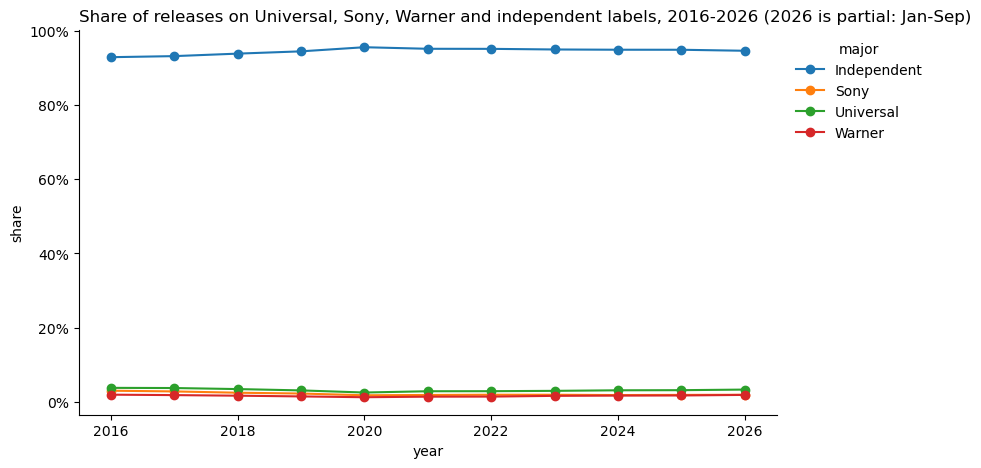

In [6]:
major_share = label_power.major_share_by_year(release_labels, tagged).toPandas().sort_values(["year", "major"])
viz.plot_lines(
    major_share, "year", "share", "major", percent=True,
    title="Share of releases on Universal, Sony, Warner and independent labels, 2016-2026 (2026 is partial: Jan-Sep)",
)

,year,major,n_releases,n_year,share
1,2016,Independent,357853,385281,0.928810
0,2016,Sony,11622,385281,0.030165
38,2016,Universal,14580,385281,0.037843
35,2016,Warner,7507,385281,0.019484
22,2025,Independent,266506,280882,0.948818
6,2025,Sony,5297,280882,0.018858
19,2025,Universal,8875,280882,0.031597
25,2025,Warner,4869,280882,0.017335


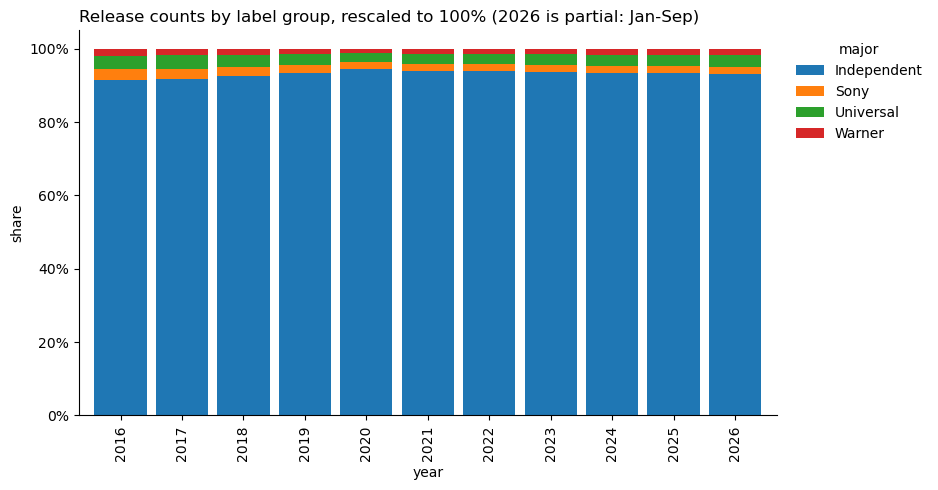

In [7]:
# A release on labels of two groups counts in both, so the bars are rescaled to 100% of group memberships.
viz.plot_stacked_share(
    major_share, "year", "n_releases", "major",
    title="Release counts by label group, rescaled to 100% (2026 is partial: Jan-Sep)",
)
major_share[major_share.year.isin([2016, 2025])]

## 4. Artist concentration per label

In [8]:
real_artists = release_artists.where(~F.col("artist_id").isin(list(networks.PLACEHOLDER_ARTIST_IDS)))  # drop "Various", "Unknown Artist"
concentration = label_power.artist_concentration(release_labels, real_artists, min_releases=50)
concentration.join(tagged.select("label_id", "major"), "label_id").groupBy("major").agg(
    F.count("*").alias("n_labels"), F.avg("hhi").alias("mean_hhi"), F.avg("top_artist_share").alias("mean_top_share")
).show()

+-----------+--------+-------------------+-------------------+
|      major|n_labels|           mean_hhi|     mean_top_share|
+-----------+--------+-------------------+-------------------+
|  Universal|     267|0.09897500756880548| 0.2131558557288048|
|     Warner|     156|0.09861673742542174|0.19328505134355195|
|       Sony|     178| 0.1124481405925554|0.22648162257032756|
|Independent|   15124|0.13019810584230407|0.23256652232637134|
+-----------+--------+-------------------+-------------------+



## 5. Top producers and writers per label

In [9]:
producers = label_power.top_contributors(release_labels, release_credits, config.PRODUCTION_ROLES, top_n=10)
writers = label_power.top_contributors(release_labels, release_credits, config.WRITING_ROLES, top_n=10)
producers.orderBy("label_id", "rank").show(20, truncate=False)

+--------+---------------------+---------+-------------------+----------+----+-------------------+
|label_id|label_name           |artist_id|artist_name        |n_releases|rank|share              |
+--------+---------------------+---------+-------------------+----------+----+-------------------+
|1       |Planet E             |3961404  |Christophe Chapelle|29        |1   |0.6304347826086957 |
|1       |Planet E             |871      |Carl Craig         |12        |2   |0.2608695652173913 |
|1       |Planet E             |5631321  |Johann Pätzold     |7         |3   |0.15217391304347827|
|1       |Planet E             |3423970  |Joachim Olaya      |6         |4   |0.13043478260869565|
|1       |Planet E             |911845   |Mathieu Berthet    |5         |5   |0.10869565217391304|
|1       |Planet E             |119      |Terrence Parker    |4         |6   |0.08695652173913043|
|1       |Planet E             |335219   |Eric Morgeson      |4         |7   |0.08695652173913043|
|1       |

In [10]:
# Check: the roles in config.PRODUCTION_ROLES / WRITING_ROLES were confirmed against these counts in T04.
release_credits.groupBy("role").count().orderBy(F.desc("count")).show(40, truncate=False)

+------------------+-------+
|role              |count  |
+------------------+-------+
|Written-By        |1805372|
|Producer          |1482212|
|Vocals            |1027744|
|Featuring         |991708 |
|Mixed By          |858279 |
|Mastered By       |820089 |
|Guitar            |788185 |
|Composed By       |663840 |
|Drums             |657596 |
|Recorded By       |621889 |
|Remix             |606689 |
|Lyrics By         |583053 |
|Engineer          |574534 |
|Bass              |560994 |
|Music By          |498329 |
|Backing Vocals    |433433 |
|Photography By    |415860 |
|Artwork           |388406 |
|Arranged By       |378194 |
|Performer         |368776 |
|Design            |319010 |
|Keyboards         |302074 |
|Percussion        |273738 |
|Piano             |259024 |
|Written By        |219507 |
|Violin            |208520 |
|Electric Guitar   |151993 |
|Layout            |147611 |
|Liner Notes       |145750 |
|Lead Vocals       |143237 |
|Songwriter        |142992 |
|Management   

`top_contributors` counts credits at both levels: release-level credits (whole release) and track-level credits (single tracks). The next cell shows how many releases have a writer credit at each level.

In [11]:
writer_levels = label_power.credit_level_coverage(release_credits, config.WRITING_ROLES).toPandas()
writer_levels.pivot(index="year", columns="level", values="n_releases")

level,any,release,track
year,,,
2016,99385,69008,38018
2017,101888,70107,38730
2018,101650,71167,37427
2019,101492,71370,36597
2020,108506,78689,36396
2021,105312,75294,36351
2022,98733,70995,33886
2023,92652,67495,30933
2024,82150,59071,27936


## 6. Concentration of the whole major tree

Pools every label in a major's tree, so a release on two Universal labels counts once. Compare with the per-label means in section 4: a tree has many artists, so its HHI is far lower than that of its single labels. `by_year` shows the trend; 2026 has fewer releases (Jan-Sep), which pushes HHI up.

In [12]:
tree_concentration = label_power.group_concentration(release_labels, real_artists, tagged, group_col="major", min_releases=50)
tree_concentration.toPandas().sort_values("major")

,major,n_pairs,n_artists,top_artist_id,top_artist_name,top_artist_share,hhi
3,Independent,4068511,897929,6351861,THIS IS WHAT I HEAR WHEN YOU TALK,0.000839,0.000014
0,Sony,96543,18484,45467,Pink Floyd,0.006546,0.000508
1,Universal,143478,22047,20991,The Rolling Stones,0.006092,0.000501
2,Warner,75328,13751,10263,David Bowie,0.007899,0.000751


,major,year,n_pairs,n_artists,top_artist_id,top_artist_name,top_artist_share,hhi
32,Independent,2016,395455,188063,10263,David Bowie,0.000895,0.000022
8,Independent,2025,303948,134625,15661965,U.A. (3),0.001540,0.000035
24,Sony,2016,13731,5288,45467,Pink Floyd,0.015512,0.000919
28,Sony,2025,5779,2075,45467,Pink Floyd,0.012459,0.001564
11,Universal,2016,16869,5292,20991,The Rolling Stones,0.007647,0.000783
5,Universal,2025,10316,3289,2171152,The Weeknd,0.007367,0.001139
15,Warner,2016,9066,3093,10263,David Bowie,0.009707,0.001187
34,Warner,2025,5637,1982,246650,The Grateful Dead,0.011176,0.001833


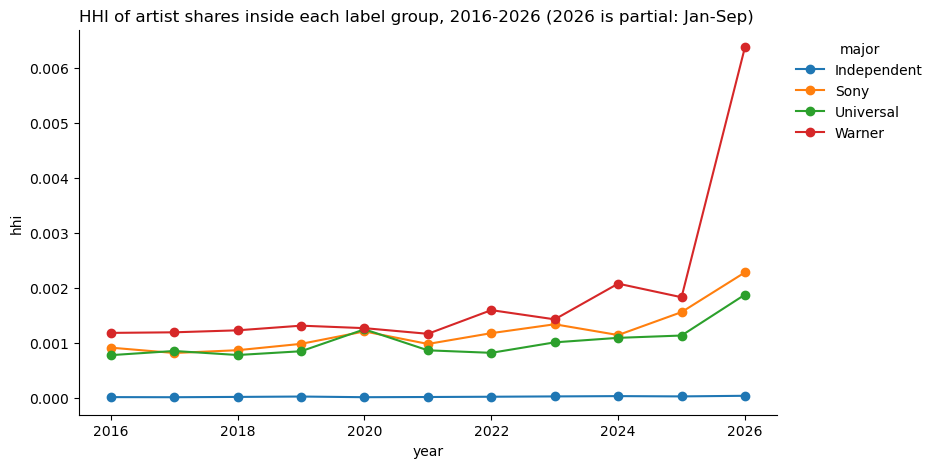

In [13]:
tree_by_year = label_power.group_concentration(
    release_labels, real_artists, tagged, group_col="major", min_releases=50, by_year=True
).toPandas().sort_values(["major", "year"])
viz.plot_lines(
    tree_by_year, "year", "hhi", "major",
    title="HHI of artist shares inside each label group, 2016-2026 (2026 is partial: Jan-Sep)",
)
tree_by_year[tree_by_year.year.isin([2016, 2025])]

## 7. Releases on labels with no parent information

"Independent" means "not linked to a major's tree in Discogs". A label with no parent and no children may still belong to a major whose contributors never filled in the link. This table counts distinct releases per year by the best class of their labels: `in_tree` (label has a parent or children) > `on_root_alone` > `self_released` > `unknown_label` (label id not in the labels table). `on_root_alone` is the pool where hidden major output could sit.

`self_released` holds the "Not On Label" placeholders (label 1818 and every label named "Not On Label ...", found by `self_released_label_ids`). They mean the artist released the music, not that a company did, and they hold 12.8-17.9% of each year's releases (the parent-coverage table below). Without this class, label 1818 counts as `in_tree` because its `parent_id` points to Stolen Riff Records (205754). That link is a data-entry error. A release on a placeholder and on a real label takes the real label's class.

In [14]:
self_released = label_power.self_released_label_ids(labels)
parent_cov = label_power.parent_coverage(release_labels, tagged, self_released=self_released).toPandas()
parent_cov

,year,on_root_alone,in_tree,self_released,unknown_label,n_releases,share_on_root_alone,share_in_tree,share_self_released,share_unknown_label
0,2016,144675,175989,64557,60,385281,0.375505,0.456781,0.167558,0.000156
1,2017,148978,179375,61930,72,390355,0.381647,0.459518,0.158650,0.000184
2,2018,153303,178632,64718,57,396710,0.386436,0.450284,0.163137,0.000144
3,2019,156630,173627,63659,100,394016,0.397522,0.440660,0.161565,0.000254
4,2020,170877,169965,74710,119,415671,0.411087,0.408893,0.179733,0.000286
5,2021,163613,164460,63097,127,391297,0.418130,0.420295,0.161251,0.000325
6,2022,150944,154102,55663,154,360863,0.418286,0.427037,0.154250,0.000427
7,2023,146946,151141,48759,219,347065,0.423396,0.435483,0.140490,0.000631
8,2024,133913,135411,42456,399,312179,0.428962,0.433761,0.135999,0.001278
9,2025,125589,119105,35973,215,280882,0.447124,0.424039,0.128072,0.000765


## Decisions to carry into `main.ipynb`

Filled in from the full-data runs in `executed/`. Each line should end up as a sentence in the report's methodology or limitations.

- [x] Root labels of the majors: Universal Music Group 38404, Sony Corporation 353657 and Warner Music Group 2345 (`config.MAJOR_ROOT_IDS`). Universal and Warner sit under the nameless placeholder label 212, which is not followed (`config.PLACEHOLDER_LABEL_IDS`). The trees hold 8,080, 3,633 and 3,087 labels.
- [x] `max_depth`: 12. 2,425,097 labels reach a root and 978 do not; 665 of these stop at depth 12, most likely because of loops in the parent links.
- [x] Minimum size for the concentration measures: 50 release-artist pairs per label (`min_releases=50`), which keeps 267 Universal, 178 Sony, 156 Warner and 15,124 independent labels.
- [x] Role lists: producers and engineers are `config.PRODUCTION_ROLES` (Producer, Co-producer, Executive-Producer, Engineer, Mixed By, Mastered By, Recorded By, Remastered By, Lacquer Cut By); writers are `config.WRITING_ROLES` (Written-By, Written By, Composed By, Lyrics By, Music By, Songwriter). Checked against the role counts, where Written-By (1,805,372) and Producer (1,482,212) are the two most common roles.